# Modelo Preditivo de Falha de Porta (7 dias)

A pergunta que o modelo tenta responder é: considerando o histórico recente de alarmes e manutenção de uma porta, qual a probabilidade de ela quebrar nos próximos 7 dias?

Este notebook testa essa hipótese com o modelo Random Forest, que foi escolhido por lidar bem com relações não lineares e por permitir interpretar o resultado com SHAP.

A lógica do fluxo é:
1. montar uma tabela porta-dia com as features que fazem sentido para manutenção;
2. treinar o modelo e verificar quais variáveis ele realmente usa;
3. remover as features fracas e comparar a performance final.

A saída é binária: a porta vai falhar / não vai falhar nos próximos 7 dias.


## 1. Como a tabela foi montada

A junção das quatro bases já tratadas na Sprint 1 (Alarmes, ZM01, ZM02, ZM03) foi feita no arquivo `construir_painel.py`, que gera `painel.parquet`.

Resumo do que o script fez:

- O que foi analisado: 480 portas individuais em 10 estações, durante 2 anos de histórico (gerando cerca de 307 mil registros de porta por dia).
- Como os dados foram cruzados: Usou-se um código padrão (Estação + Via + Número da Porta) extraído via texto das duas bases de dados.
- O foco principal: O alarme da porta (PDM), que é a peça que falha e gera ordem de manutenção, e não o painel central (MDU).
- A meta do modelo: Prever se uma porta específica vai precisar de manutenção corretiva (ordem ZM01) nos próximos 1 a 7 dias.
- Cuidados tomados: Nenhuma informação do próprio dia ou do futuro foi usada para criar os indicadores, garantindo que o modelo aprenda com o passado real (a taxa média de falhas identificada foi de 8,09%).




## 2. Features candidatas e por que cada grupo faz sentido

Aqui foi pensado as melhores features para o modelo encontrar uma falha.

| Grupo | Exemplos | Por que faz sentido |
|---|---|---|
| Alarmes por tipo, janela móvel (1/3/7/14/30d) | `n_LSD_7d`, `n_FC_30d`, `n_CA_14d`... | Cada tipo de alarme marca um sintoma diferente de desgaste; janelas diferentes mostram se o problema é recente ou crônico. |
| Duração do alarme | `dur_max_7d`, `dur_max_30d` | Alarme que demora mais pra normalizar geralmente indica defeito mais sério que um pico rápido. |
| Recência | `n_total_decaido_h7`, `n_LSD_decaido_h7` | Alarme de ontem pesa mais que alarme de 3 semanas atrás — o problema tende a se agravar com o tempo. |
| Alarme do módulo de plataforma | `n_mdu_7d` | Sinal auxiliar: não é da porta em si, mas pode indicar problema compartilhado entre portas da mesma via. |
| Histórico SAP | `dias_desde_zm01`, `zm01_90d`, `zm02_30d`, `zm03_90d` | Porta que já teve correção recente ou recorrente tende a voltar a falhar. |
| Identificação | `est_cod`, `via_cod`, `num_porta` | Captura efeito de estação e de posição que nenhuma outra feature cobre. |

### Features criadas

Além das colunas acima, foi combinado algumas delas pra resumir um padrão que não aparece bem numa coluna isolada:

- Mudança recente (rampa_7d): Mostra se os alarmes estão acelerando na última semana em comparação com a semana anterior.
- Comportamento fora do comum (razao_7d_30d): Identifica se a porta está falhando mais do que o seu padrão normal do último mês (destaca portas "calmas" que começaram a dar problema).
- Filtro de alarmes reais (frac_tecnicos_30d): Separa as falhas OBS mecânica/técnica real de simples observações ou ruídos sem defeito.
- Localização (est_cod / via_cod): Códigos numéricos para o modelo saber em qual estação e via a porta está localizada.

### Features de ciclo/recorrência

Uma ideia implementada que parecia fazer sentido testar é: quanto tempo faz desde a última corretiva, e com que frequência aquela porta costuma quebrar. A intuição é a de desgaste por ciclo. Depois de um concerto, a porta vai durar um tempo antes de quebrar de novo

- **dias_desde_ultima_corretiva**: dias desde a última ZM01 ou ZM02, o que for mais recente.
- **n_corretivas_historico_total**: quantas corretivas essa porta já teve até aquele dia.
- **intervalo_medio_zm01**: intervalo médio, até aquele dia, entre as corretivas ZM01 daquela porta, o ritmo normal de quebra dela.
- **razao_atraso_zm01**: dias_desde_zm01 / intervalo_medio_zm01. Então acima de 1 significa que a porta já está atrasada em relação ao próprio ciclo.

### Duas decisões de exclusão

- **Horário de pico** Não entrou, porque o modelo esta analisando uma semana inteira, e não um dia.
- **Normalização (StandardScaler)** Não foi necessário porque o modelo de Random Forest decide por cortes de valor em cada feature, então a escala da coluna não influencia o modelo (mais detalhe na seção 4).


In [ ]:
import re
import pandas as pd, numpy as np

painel = pd.read_parquet('painel.parquet')

# recarrega as ordens ZM01 (mesma regex de construir_painel.py) so para montar
# as features de ciclo/recorrencia abaixo -- nao repete o parsing do restante do painel
PAT_LOC = re.compile(r'^SP04-6-PSD-([A-Z]{3})(?:-PLT(\d)|-P(\d)S\d)?(?:-PP(\d{2})(PDM|PFX|PSE))?')


def carrega_ordens(caminho, aba):
    df = pd.read_excel(caminho, aba)
    m = df['local_de_instalacao'].apply(lambda s: PAT_LOC.match(s) if isinstance(s, str) else None)
    df['est'] = [x.group(1) if x else None for x in m]
    df['via'] = [(x.group(2) or x.group(3)) if x else None for x in m]
    df['porta'] = [int(x.group(4)) if x and x.group(4) else None for x in m]
    df = df.dropna(subset=['est', 'via', 'porta', 'inicio_avaria_datetime']).copy()
    df['porta'] = df['porta'].astype(int)
    df['id_porta'] = df['est'] + '_' + df['via'] + '_' + df['porta'].astype(str).str.zfill(2)
    df['Data'] = pd.to_datetime(df['inicio_avaria_datetime']).dt.normalize()
    return df


zm01 = carrega_ordens('../../data/Corretiva Emergencial/processados/ZM01_limpa.xlsx', 'ZM01_limpa')

# contagem historica total e intervalo medio entre corretivas -- causal (so eventos < t)
ev = zm01[['id_porta', 'Data']].dropna().drop_duplicates().sort_values(['id_porta', 'Data']).reset_index(drop=True)
ev['ordem'] = ev.groupby('id_porta').cumcount() + 1
ev['diff'] = ev.groupby('id_porta')['Data'].diff().dt.days
ev['intervalo_medio_ate_aqui'] = ev.groupby('id_porta')['diff'] \
    .apply(lambda s: s.expanding().mean()).reset_index(level=0, drop=True)

p = painel[['id_porta', 'Data']].copy()
p['_idx'] = painel.index  # merge_asof descarta o indice; ele viaja como coluna
m = pd.merge_asof(p.sort_values('Data'),
                   ev[['id_porta', 'Data', 'ordem', 'intervalo_medio_ate_aqui']].sort_values('Data'),
                   on='Data', by='id_porta', direction='backward', allow_exact_matches=False)
painel['n_corretivas_historico_total'] = pd.Series(m['ordem'].values, index=m['_idx'].values) \
    .reindex(painel.index).fillna(0)
_interv = pd.Series(m['intervalo_medio_ate_aqui'].values, index=m['_idx'].values).reindex(painel.index)
painel['intervalo_medio_zm01'] = _interv.fillna(_interv.median())
painel['razao_atraso_zm01'] = painel['dias_desde_zm01'] / painel['intervalo_medio_zm01']
painel['dias_desde_ultima_corretiva'] = painel[['dias_desde_zm01', 'dias_desde_zm02']].min(axis=1)

cols_ciclo = ['dias_desde_ultima_corretiva', 'n_corretivas_historico_total',
              'intervalo_medio_zm01', 'razao_atraso_zm01']
print(painel[cols_ciclo].describe().round(1).T.to_string())

                                 count   mean     std  min   25%   50%    75%     max
dias_desde_ultima_corretiva   306864.0  310.3  1406.3  1.0  25.0  65.0  150.0  9999.0
n_corretivas_historico_total  306864.0    8.0     6.7  0.0   3.0   6.0   11.0    57.0
intervalo_medio_zm01          306864.0   85.9    75.9  1.0  46.2  65.6   96.0   886.0
razao_atraso_zm01             306864.0    8.4    30.3  0.0   0.4   1.0    2.6   256.0


In [ ]:
# features derivadas ja existentes (ver justificativa na secao anterior)
painel['rampa_7d'] = painel['n_total_7d'] - (painel['n_total_14d'] - painel['n_total_7d'])
painel['razao_7d_30d'] = painel['n_total_7d'] / (painel['n_total_30d'] / 4 + 1)
painel['frac_tecnicos_30d'] = painel['n_tecnicos_30d'] / (painel['n_total_30d'] + 1)
painel['est_cod'] = painel['est'].astype('category').cat.codes
painel['via_cod'] = painel['via'].astype(int)

EXCLUI = {'id_porta', 'Data', 'est', 'via', 'id_plat', 'y', 'n_falhas_7d_futuro', 'cobertura_30d', 'mes'}
FEATS = [c for c in painel.columns if c not in EXCLUI]
print(f'{len(FEATS)} features candidatas (79 da versão anterior + 4 de ciclo/recorrência)')

83 features candidatas (79 da versão anterior + 4 de ciclo/recorrência)


## 3. Separação treino/teste

Normalmente a divisão de dados para treino e teste seria 80/20%, porém aqui, a divisão entre treino e teste foi feita por data (passado vs. futuro), e não aleatoriamente, para simular o uso do modelo na vida real e evitar o vazamento de dados. O motivo do porque não dividir ao acaso foi que, como os dados usam médias dos últimos 30 dias, dias vizinhos são quase idênticos. Misturar eles faria o modelo "decorar" o teste, criando uma falsa sensação de alta precisão.

Divisão temporal: O modelo treina com o passado e é testado no futuro.

Margem de segurança (folga de 7 dias): Foi deixado um intervalo de 7 dias entre o treino e o teste para garantir que nenhuma informação da janela de previsão se cruze entre as duas etapas.

Ajuste de alertas (limiar): A sensibilidade para emitir alertas é configurada usando apenas os dados de treino, sem olhar os resultados do teste.


In [ ]:
FIM_TREINO, INI_TESTE, INI_VALID = (pd.Timestamp('2025-04-23'), pd.Timestamp('2025-05-01'),
                                          pd.Timestamp('2025-01-31'))
treino = painel[painel['Data'] <= FIM_TREINO]
teste = painel[painel['Data'] >= INI_TESTE]
tr_fit = treino[treino['Data'] <= INI_VALID - pd.Timedelta(days=8)]
tr_val = treino[treino['Data'] >= INI_VALID]

print(f'treino: {len(treino):,} linhas | teste: {len(teste):,} linhas')
print(f'taxa de falha treino: {treino["y"].mean()*100:.2f}% | teste: {teste["y"].mean()*100:.2f}%')

treino: 232,992 linhas | teste: 71,184 linhas
taxa de falha treino: 7.90% | teste: 8.71%


## 4. Como o Random Forest funciona

O Random Forest é um algoritmo de aprendizado de máquina supervisionado que combina as previsões de múltiplas árvores de decisão para gerar um resultado final mais preciso e estável, funcionando tanto para classificação quanto para regressão.
Ele lida com o problema de overfitting criando diversidade entre as árvores através de dois mecanismos:

- Seleção de dados: Cada árvore é treinada com uma amostra aleatória das linhas do conjunto original.
- Seleção de variáveis: Em cada divisão da árvore, apenas um subconjunto aleatório das colunas é considerado.


Pra esse problema, o Random Forest foi escolhido por três motivos práticos:
- Ele lida bem com combinações de sinais sem precisar criar a combinação manualmente;
- Não precisa normalizar os dados;
- Combina bem com SHAP (o TreeExplainer é exato e rápido pra árvores), o que permite abrir a caixa-preta na próxima seção.

### Parâmetros escolhidos

- n_estimators=400: número de árvores no forest. 400 é o suficiente pra média das previsões
  ficar estável (o modelo para de melhorar significativamente depois desse numero).
- max_depth=14: limita quão fundo cada árvore pode crescer. Sem esse limite, a árvore cresceria
  até decorar cada linha do treino; com ~300 mil linhas isso ia gerar uma árvore muito grande e sobreajustada.
- min_samples_leaf=40: cada folha da árvore precisa ter pelo menos 40 linhas por trás dela.
  Isoo faz com que o modelo crie regras baseadas em pouco casos, isso é importante porque
  falha é um evento raro, então é fácil encontrar um padrão em algumas linhas que
  na verdade é só ruído.
- random_state=42: fixa a aleatoriedade (amostragem de linhas e de features de cada árvore) pra
  o resultado ser reprodutível.


### Busca de hiperparâmetros

Os parâmetros até aqui foram escolhidos manualmente, com base no que fazia sentido pro problema, eles não vieram de uma busca automatizada. Foi pensado para um próximo passo, testar um `RandomizedSearchCV`, para tentar achar hiperparametros diferentes (`n_estimators`, `max_depth`, `min_samples_leaf`) e ver se o modelo performa melhor.

Porém foi descoberto que, o RandomizedSearchCV (assim como o `GridSearchCV`) precisa validar cada combinação de parâmetros em algum recorte dos dados antes de decidir qual é a melhor. Por padrão essa validação usa K-Fold aleatório, que embaralha as linhas. Entretanto isso leva ao mesmo problema da seção 3, porque as features de janela móvel fariam dias vizinhos vazarem informação entre treino e validação dentro da busca.

Por isso a busca vai utilizar `TimeSeriesSplit` como cv. No lugar de embaralhar, o TimeSeriesSplit corta o treino em pedaços sequenciais, sempre validando num período que vem depois do treino daquele fold, sem tocar no teste real.

Depois do RandomizedSearchCV (mais rápido, testando um número escolhido de combinações), o plano é rodar um GridSearchCV perto do melhor resultado encontrado, pra comparar se a busca mais completa muda algo ou só confirma o que o random search já achou.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score, confusion_matrix)


def melhor_limiar(y, prob):
    grid = np.unique(np.quantile(prob, np.linspace(0.50, 0.999, 200)))
    return max(((f1_score(y, (prob >= t).astype(int), zero_division=0), t) for t in grid))[1]


def avalia(nome, yte, pred, prob):
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    return {'modelo': nome, 'precisao': precision_score(yte, pred, zero_division=0),
            'recall': recall_score(yte, pred, zero_division=0), 'f1': f1_score(yte, pred, zero_division=0),
            'pr_auc': average_precision_score(yte, prob), 'roc_auc': roc_auc_score(yte, prob),
            'alertas': int(pred.sum()), 'tp': int(tp), 'fp': int(fp), 'fn': int(fn)}


def treina_avalia(feats, tag):
    Xtr, ytr, Xte, yte = treino[feats], treino['y'], teste[feats], teste['y']
    mod = RandomForestClassifier(n_estimators=400, max_depth=14, min_samples_leaf=40,
                                  class_weight='balanced', n_jobs=-1, random_state=42)
    mod.fit(tr_fit[feats], tr_fit['y'])
    lim = melhor_limiar(tr_val['y'], mod.predict_proba(tr_val[feats])[:, 1])
    mod.fit(Xtr, ytr)
    prob = mod.predict_proba(Xte)[:, 1]
    pred = (prob >= lim).astype(int)
    linha = avalia(tag, yte, pred, prob)
    print(f'[{tag}] limiar={lim:.4f}')
    print(pd.DataFrame([linha]).round(3).to_string(index=False))
    return mod, prob, lim, linha


mod_full, prob_full, lim_full, linha_full = treina_avalia(FEATS, 'Random Forest (todas as features)')

[Random Forest (todas as features)] limiar=0.5147
                           modelo  precisao  recall    f1  pr_auc  roc_auc  alertas   tp    fp   fn
Random Forest (todas as features)     0.156   0.565 0.245   0.186    0.696    22391 3503 18888 2699


## 5. Interpretando com SHAP

O SHAP é uma ferramenta usada para tentar explicar como um modelo toma decisões. Ela mostra o quanto cada dado ou variável contribuiu para um resultado específico.

A ideia aqui é ver quais features mais impactam a predição e se seu valor alto ou baixo, puxa o risco para cima ou para baixo.


In [ ]:
import shap

amostra = teste.sample(n=4000, random_state=42)
explainer = shap.TreeExplainer(mod_full)
sv = explainer.shap_values(amostra[FEATS])
if isinstance(sv, list):
    sv = sv[1]
if sv.ndim == 3:
    sv = sv[:, :, 1]

imp = pd.DataFrame({'feature': FEATS, 'shap_abs_medio': np.abs(sv).mean(axis=0)}) \
    .sort_values('shap_abs_medio', ascending=False).reset_index(drop=True)
print(imp.head(15).to_string(index=False))

                     feature  shap_abs_medio
n_corretivas_historico_total        0.038637
                 dur_max_30d        0.032956
                  dur_max_7d        0.017488
        intervalo_medio_zm01        0.014037
             dias_desde_zm01        0.012639
 dias_desde_ultima_corretiva        0.012392
                    zm01_90d        0.009761
           frac_tecnicos_30d        0.009409
               n_tecnicos_3d        0.008295
                  n_total_3d        0.008255
                     est_cod        0.006982
                    n_FC_30d        0.006132
               n_tecnicos_7d        0.006123
                    n_FC_14d        0.005436
                    zm01_30d        0.005128


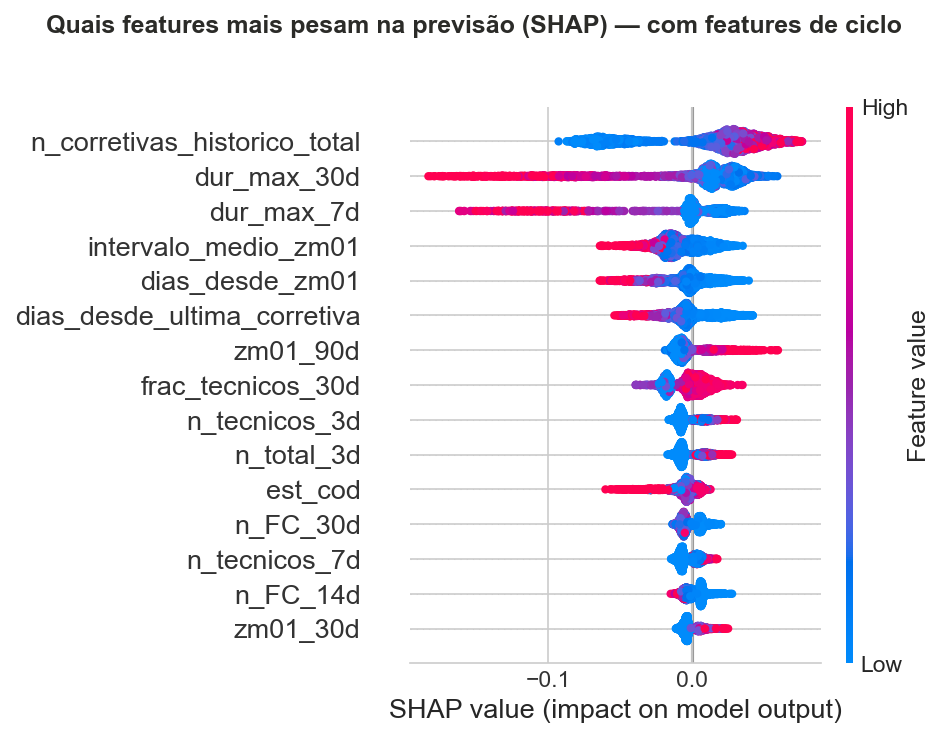

In [ ]:
shap.summary_plot(sv[:, [FEATS.index(c) for c in imp.head(15)['feature']]],
                   amostra[imp.head(15)['feature']], show=True)

Foi possível ver que as features mais importantes do modelo são as relacionadas a histórico de falha e duração do alarme. Isso parece fazer sentido, já que uma porta que já falhou várias vezes, ou que tem alarme mais persistente tende a ter risco maior. A cor também parece ir para a direção esperada. Os valores altos empurram o risco para cima; valores baixos empurram para baixo.


## 6. Removendo o que não ajuda

Aqui foi analisado as features que menos impactavam o modelo. Ja que elas não ajudavam muito o modelo, elas foram removidas por custar processamento, e para que o modelo pudesse focar em outra features.

Isso removeu as features fracas, principalmente contagens raras em janelas curtas (1 ou 3 dias) e as que não acrescentam informação nova.


In [ ]:
limiar_corte = imp['shap_abs_medio'].iloc[0] * 0.01
mantidas = imp[imp['shap_abs_medio'] >= limiar_corte]['feature'].tolist()
removidas = imp[imp['shap_abs_medio'] < limiar_corte]['feature'].tolist()
print(f'corte em {limiar_corte:.5f} (1% do shap da feature mais forte)')
print(f'mantidas: {len(mantidas)} | removidas: {len(removidas)}')
print('removidas:', removidas)

corte em 0.00039 (1% do shap da feature mais forte)
mantidas: 71 | removidas: 12
removidas: ['n_CSD_3d', 'n_FO_3d', 'zm02_30d', 'n_RCE_7d', 'n_FO_1d', 'n_OA_1d', 'dia_semana', 'n_RCE_3d', 'n_CSD_1d', 'n_CA_1d', 'fim_de_semana', 'n_RCE_1d']


As 12 features removidas parecem seguir o mesmo padrão. Quase todas são contagens raras em janela curta, com pouco sinal estatístico, e também saíram as duas features de calendário.


In [ ]:
mod_final, prob_final, lim_final, linha_final = treina_avalia(mantidas, 'Random Forest (features selecionadas)')

R = pd.DataFrame([linha_full, linha_final])
print()
print(R.round(3).to_string(index=False))

[Random Forest (features selecionadas)] limiar=0.5183
                               modelo  precisao  recall    f1  pr_auc  roc_auc  alertas   tp    fp   fn
Random Forest (features selecionadas)     0.159   0.553 0.247   0.185    0.697    21564 3432 18132 2770

                               modelo  precisao  recall    f1  pr_auc  roc_auc  alertas   tp    fp   fn
    Random Forest (todas as features)     0.156   0.565 0.245   0.186    0.696    22391 3503 18888 2699
Random Forest (features selecionadas)     0.159   0.553 0.247   0.185    0.697    21564 3432 18132 2770


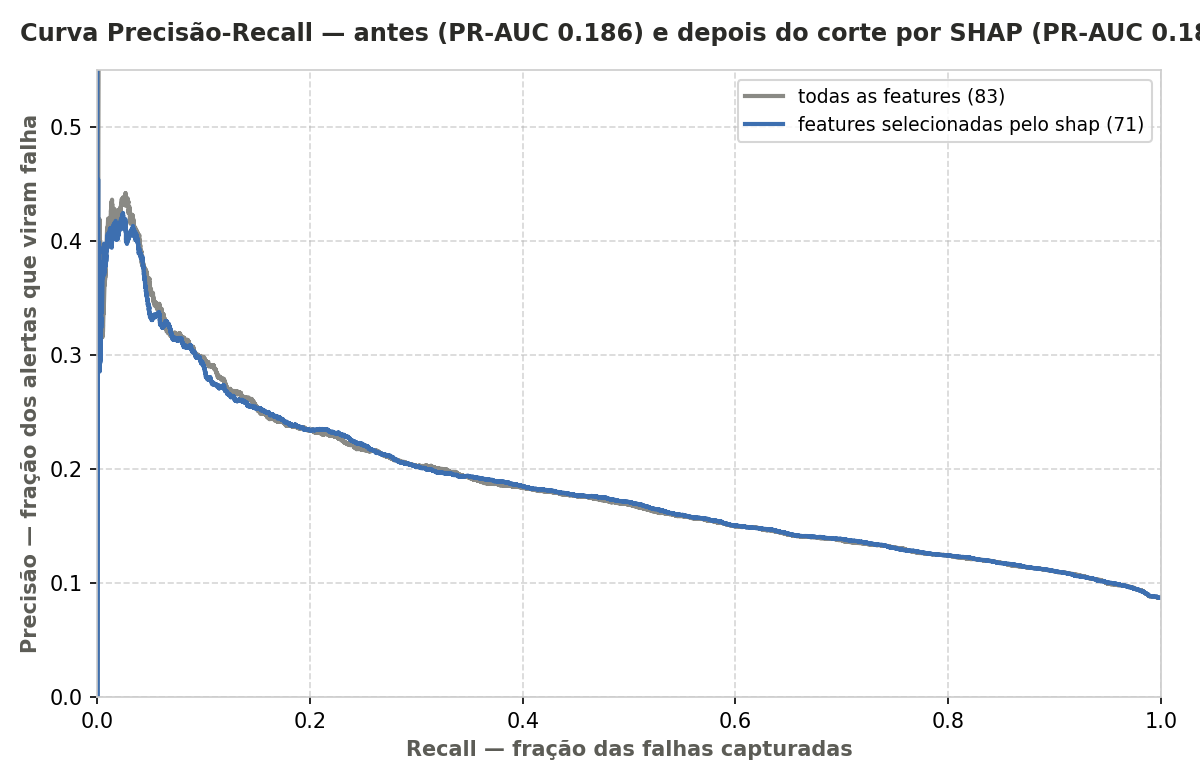

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

prec_full, rec_full, _ = precision_recall_curve(teste['y'], prob_full)
prec_sel, rec_sel, _ = precision_recall_curve(teste['y'], prob_final)
plt.plot(rec_full, prec_full, label=f'todas as features (83) — PR-AUC {linha_full["pr_auc"]:.3f}')
plt.plot(rec_sel, prec_sel, label=f'selecionadas pelo SHAP (71) — PR-AUC {linha_final["pr_auc"]:.3f}')
plt.xlabel('Recall'); plt.ylabel('Precisão'); plt.legend(); plt.show()

### Métricas por linha (porta-dia)

| Modelo | Precisão | Recall | F1 | PR-AUC | ROC-AUC | Alertas emitidos | Acertos (TP) | Falsos alarmes (FP) | Falhas perdidas (FN) |
|---|---|---|---|---|---|---|---|---|---|
| Todas as features (83) | 0,156 | 0,565 | 0,245 | 0,186 | 0,696 | 22.391 | 3.503 | 18.888 | 2.699 |
| **Selecionadas pelo SHAP (71)** | 0,159 | **0,553** | **0,247** | 0,185 | **0,697** | 21.564 | 3.432 | 18.132 | 2.770 |

As features de ciclo foram as criadas na seção 2: `dias_desde_ultima_corretiva`, `n_corretivas_historico_total`,
`intervalo_medio_zm01` e `razao_atraso_zm01`. Elas foram as principais responsáveis pela melhora de
recall desta versão em relação à anterior, porque capturam se a porta já está
atrasada em relação ao próprio histórico de quebra, e não só quanto ela alarmou recentemente.

O que precisão e recall significam neste modelo:
- Recall: das falhas que realmente aconteceram, quantas o modelo conseguiu antecipar com pelo
  menos um alerta? Recall baixo = falha real que o modelo não viu, sem nenhum aviso.
- Precisão: dos alertas que o modelo emitiu, quantos realmente viraram falha? Precisão baixa =
  manutenção sendo acionada muitas vezes à toa, pra uma porta que no fim não quebrou.

Essa métrica, porém, é calculada por linha porta-dia, o modelo tenta acertar exatamente o dia que quebrou, isso é resolvido na seção abaixo.


## 7. Busca de hiperparâmetros

Os parâmetros usados no modelo até aqui vieram de conhecimento de domínio e não de uma busca sistemática. Essa seção testa um RandomizedSearchCV com TimeSeriesSplit como cv (pelos motivos explicados na seção 4), seguido de um GridSearchCV perto do melhor resultado encontrado, pra ver se alguma outra combinação de parâmetros supera a atual.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, TimeSeriesSplit

treino_ord = treino.sort_values('Data')
X_search, y_search = treino_ord[mantidas], treino_ord['y']

espaco_busca = {
    'n_estimators': [200, 300, 400, 500],
    'max_depth': [8, 10, 12, 14, 16, None],
    'min_samples_leaf': [10, 20, 40, 60, 100],
    'max_features': ['sqrt', 'log2', 0.3, 0.5],
}

tscv = TimeSeriesSplit(n_splits=3)

random_search = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_distributions=espaco_busca,
    n_iter=15,
    cv=tscv,
    scoring='average_precision',
    random_state=42,
    n_jobs=1,
)
random_search.fit(X_search, y_search)
print('melhor PR-AUC (validação cruzada):', round(random_search.best_score_, 4))
print('melhores parâmetros:', random_search.best_params_)

melhor PR-AUC (validação cruzada): 0.1835
melhores parâmetros: {'n_estimators': 300, 'min_samples_leaf': 100, 'max_features': 'log2', 'max_depth': 14}


In [ ]:
_, _, _, linha_random = treina_avalia(mantidas, 'RandomizedSearchCV', random_search.best_params_)
print(pd.DataFrame([linha_final, linha_random]).round(3).to_string(index=False))

                               modelo  precisao  recall    f1  pr_auc  roc_auc  alertas   tp    fp   fn
Random Forest (features selecionadas)     0.159   0.553 0.247   0.185    0.697    21564 3432 18132 2770
                   RandomizedSearchCV     0.150   0.603 0.241   0.185    0.696    24846 3738 21108 2464


In [ ]:
bp = random_search.best_params_
grade = {
    'n_estimators': [200, 300, 400],
    'max_depth': [12, 14, 16],
    'min_samples_leaf': [90, 100, 110],
    'max_features': [bp['max_features']],
}

grid_search = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_grid=grade,
    cv=tscv,
    scoring='average_precision',
    n_jobs=1,
)
grid_search.fit(X_search, y_search)
print('melhor PR-AUC (validação cruzada):', round(grid_search.best_score_, 4))
print('melhores parâmetros:', grid_search.best_params_)

melhor PR-AUC (validação cruzada): 0.1841
melhores parâmetros: {'max_depth': 14, 'max_features': 'log2', 'min_samples_leaf': 110, 'n_estimators': 400}


In [ ]:
_, _, _, linha_grid = treina_avalia(mantidas, 'GridSearchCV', grid_search.best_params_)
print(pd.DataFrame([linha_final, linha_random, linha_grid]).round(3).to_string(index=False))

                               modelo  precisao  recall    f1  pr_auc  roc_auc  alertas   tp    fp   fn
Random Forest (features selecionadas)     0.159   0.553 0.247   0.185    0.697    21564 3432 18132 2770
                   RandomizedSearchCV     0.150   0.603 0.241   0.185    0.696    24846 3738 21108 2464
                         GridSearchCV     0.154   0.592 0.245   0.186    0.697    23783 3673 20110 2529


O random search e o grid search encontraram parâmetros parecidos com os escolhidos na seção 4: `max_depth=14` ficou igual nos três, e `min_samples_leaf` subiu de 40 pra ~100-110 (folhas ainda mais conservadoras), com `n_estimators` entre 300 e 400 e `max_features='log2'` no lugar do padrão (que seria próximo de `sqrt`, ~8 features por divisão vs. as ~6 do `log2`).

Nos números por linha no teste, a diferença não foi muito grande: PR-AUC e ROC-AUC sobem um pouco (0,185 → 0,186), mas o F1 fica praticamente igual (0,247 → 0,245) e a troca é a mesma de sempre, um pouco menos de precisão por um pouco mais de recall. Ou seja, a busca sistemática não achou nada estruturalmente diferente do que a escolha manual já tinha encontrado, os parâmetros atuais já estavam perto de um ótimo local pra esse problema. O grid search, por sua vez, ficou bem perto do resultado do random search (PR-AUC de validação 0,1835 → 0,1841), confirmando que a busca mais detalhada na vizinhança não trouxe ganho relevante sobre o random search.

Por essa diferença ser pequena, o modelo usado no resto do notebook (`mod_final`, seção 6) continua sendo o dos parâmetros originais.

## 8. A precisão por evento, não por linha

A métrica da seção anterior conta cada dia separadamente. Porém foi pensado que seria melhor se o modelo conseguisse responder se: quando o modelo emite um aviso para uma porta, aquele aviso caiu dentro dos 7 dias em que a porta realmente quebrou? Não sendo necessariamente no dia exato da quebra. E, por outro lado, das falhas reais, quantas tiveram algum aviso do modelo na semana anterior?

Isso acabou levando a duas mudanças nas métricas:

1. Recall por evento real: para cada ordem ZM01 de fato aberta no período de teste, verifica-se
   se o modelo alertou em pelo menos um dos 7 dias anteriores.
2. Precisão por episódio de alerta: dias consecutivos de alerta na mesma porta são agrupados em
   um único "episódio". Um episódio é considerado acerto se uma falha real acontece do início do episódio até 7 dias depois do seu
   último dia.


In [ ]:
# zm01 ja foi carregado na secao de features de ciclo -- reaproveita, nao recarrega
T = teste[['id_porta', 'Data', 'y']].copy()
T['prob'] = prob_final
T = T.sort_values(['id_porta', 'Data']).reset_index(drop=True)
T['alerta'] = (T['prob'] >= lim_final).astype(int)

INI_T, FIM_T = T['Data'].min(), T['Data'].max()
falhas_teste = zm01[(zm01['Data'] > INI_T) & (zm01['Data'] <= FIM_T + pd.Timedelta(days=7))][['id_porta', 'Data']] \
    .drop_duplicates()
falhas_teste = falhas_teste[falhas_teste['id_porta'].isin(T['id_porta'].unique())]
print(f'falhas reais (eventos) no periodo de teste: {len(falhas_teste)}')

falhas reais (eventos) no periodo de teste: 1178


In [ ]:
def teve_alerta_antes(row):
    ip, d = row['id_porta'], row['Data']
    janela = T[(T['id_porta'] == ip) & (T['Data'] >= d - pd.Timedelta(days=7)) & (T['Data'] < d)]
    return int((janela['alerta'] == 1).any())


falhas_teste['detectada'] = falhas_teste.apply(teve_alerta_antes, axis=1)
recall_evento = falhas_teste['detectada'].mean()
print(f'recall por evento: {falhas_teste["detectada"].sum()}/{len(falhas_teste)} = {recall_evento*100:.1f}%')

recall por evento: 766/1178 = 65.0%


In [ ]:
episodios = []
for ip, g in T.groupby('id_porta'):
    g = g.sort_values('Data').reset_index(drop=True)
    em_episodio = False
    for _, r in g.iterrows():
        if r['alerta'] == 1 and not em_episodio:
            em_episodio, inicio, fim_ep = True, r['Data'], r['Data']
        elif r['alerta'] == 1 and em_episodio:
            fim_ep = r['Data']
        elif r['alerta'] == 0 and em_episodio:
            episodios.append({'id_porta': ip, 'inicio': inicio, 'fim': fim_ep})
            em_episodio = False
    if em_episodio:
        episodios.append({'id_porta': ip, 'inicio': inicio, 'fim': fim_ep})

EP = pd.DataFrame(episodios)
print(f'episodios de alerta (dias consecutivos agrupados): {len(EP)}  '
      f'(vs {T["alerta"].sum()} dias de alerta individuais)')


def houve_falha_no_range(row):
    hi = row['fim'] + pd.Timedelta(days=7)
    f = zm01[(zm01['id_porta'] == row['id_porta']) & (zm01['Data'] > row['inicio']) & (zm01['Data'] <= hi)]
    return int(len(f) > 0)


EP['acertou'] = EP.apply(houve_falha_no_range, axis=1)
precisao_evento = EP['acertou'].mean()
f1_evento = 2 * precisao_evento * recall_evento / (precisao_evento + recall_evento)
print(f'precisao por episodio: {EP["acertou"].sum()}/{len(EP)} = {precisao_evento*100:.1f}%')
print(f'F1 por evento/episodio: {f1_evento:.3f}')

episodios de alerta (dias consecutivos agrupados): 1905  (vs 21564 dias de alerta individuais)
precisao por episodio: 496/1905 = 26.0%
F1 por evento/episodio: 0.372


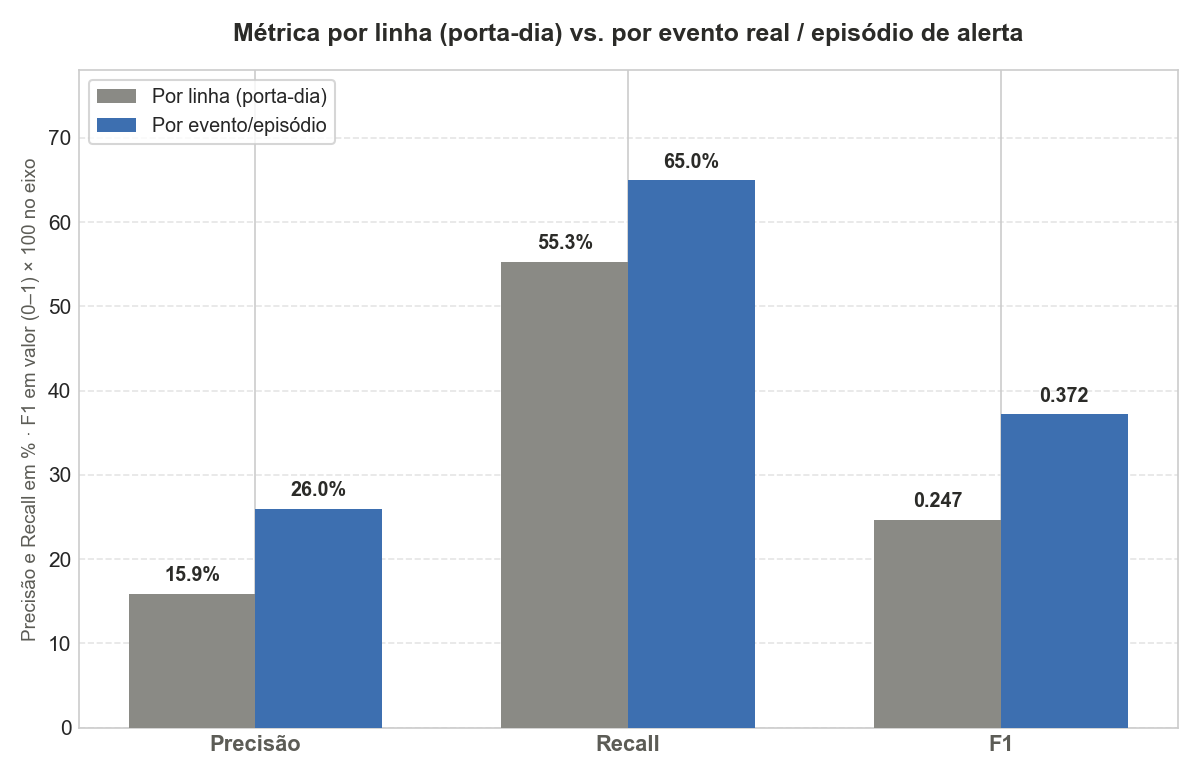

In [ ]:
plt.bar(['linha (porta-dia)', 'evento/episódio'], [linha_final['precisao']*100, precisao_evento*100])
plt.ylabel('Precisão (%)'); plt.show()

É possível observar pelo gráfico que, por evento, o modelo captura 65,0% das falhas reais (contra 55,3% na
métrica por linha), porque aqui o modelo precisa acertar um dos 7 dias antes da falha, não a maioria deles.
E, olhando por episódio de alerta em vez de por dia, a precisão sobe de 15,9% para 26,0%: os
21.564 alertas diários viram 1.905 episódios reais (a operação não reemitiria um aviso novo a cada
manhã enquanto o risco continua alto). O F1 por evento (0,372) também é bem mais alto que o F1 por
linha (0,247).

## 9. O que a feature de ciclo mudou

No gráfico abaixo é possível visualizar o impacto das features de ciclo. Portas com histórico de mais erros têm mais risco, mesmo quando os alarmes recentes não são tão altos.


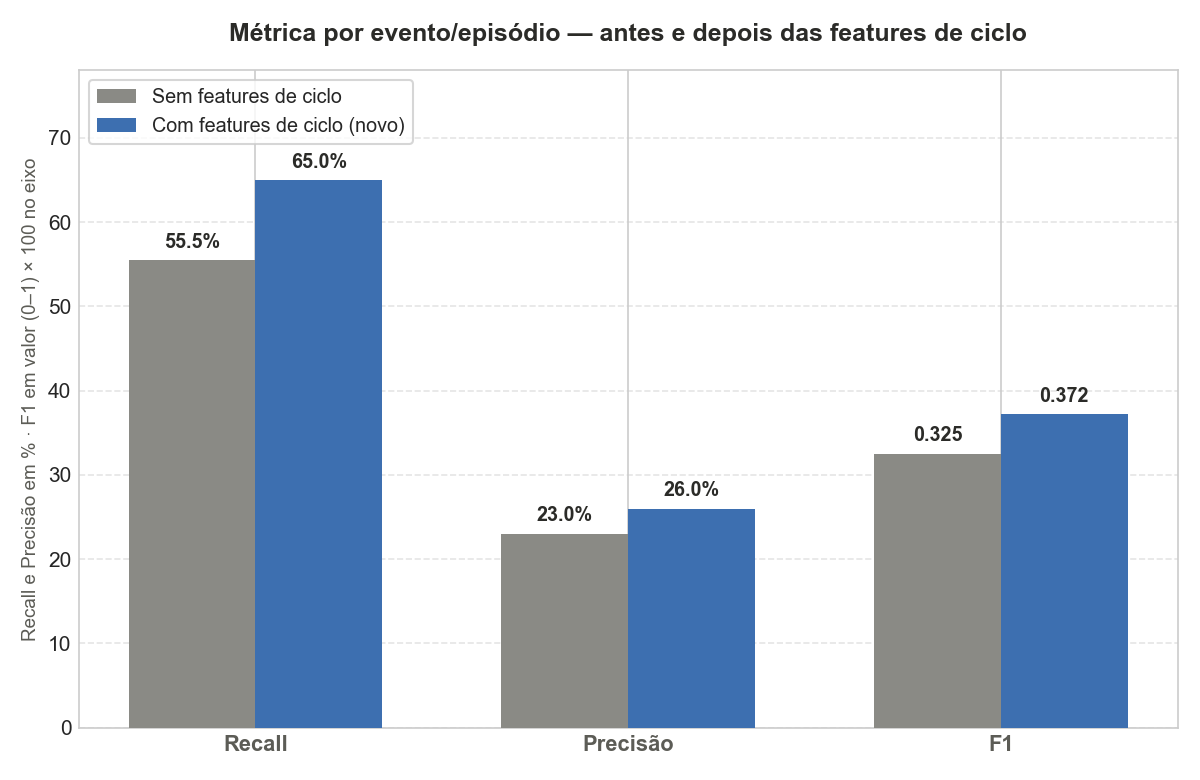

In [ ]:
plt.figure()
plt.bar(['recall', 'precisão'], [0.555 * 100, 0.230 * 100], alpha=0.5, label='sem features de ciclo')
plt.bar(['recall', 'precisão'], [0.650 * 100, 0.260 * 100], alpha=0.5, label='com features de ciclo')
plt.ylabel('%'); plt.legend(); plt.show()

## 10. Síntese

Em resumo, o fluxo deste notebook foi: primeiro a tabela porta-dia foi montada juntando Alarmes,
ZM01, ZM02 e ZM03 (seção 1); depois foram definidas as features candidatas, incluindo as de
ciclo/recorrência (seção 2); os dados foram separados em treino e teste por data, não ao acaso
(seção 3); o Random Forest foi treinado em cima desse treino (seção 4); o resultado foi interpretado
com SHAP pra ver o que o modelo realmente usa (seção 5); as features fracas foram removidas e o
modelo foi retreinado só com as que sobraram (seção 6); a busca sistemática de hiperparâmetros
confirmou que os parâmetros escolhidos já estavam perto de um ótimo (seção 7); e o modelo final foi
avaliado tanto por linha quanto por evento real, com o impacto das features de ciclo medido à parte
(seções 8 e 9).

Principais resultados:

- A tabela porta-dia já vem pronta do pipeline, unindo Alarmes, ZM01, ZM02 e ZM03 pela chave estação + via + porta.
- Foram criadas features de curto prazo e de histórico recorrente, cada uma com justificativa operacional.
- O Random Forest foi treinado e interpretado com SHAP para verificar o que de fato importa.
- A remoção feita com o SHAP removeu as features fracas sem prejudicar a performance geral.
- GridSearch e RandomizedSearch acharam hiperparametros bem próximos
- O modelo final fica mais enxuto, mais legível e mais coerente com a lógica de manutenção.
